<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week08_EDA_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- 서울공유자전거시간대별 사용데이터

In [3]:
df=pd.read_csv('https://github.com/datadigger01/datamining/raw/main/DATA/SeoulBikeData.csv', encoding='cp949')
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   object 
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(캜)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(캜)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)   8760 non-null   float64
 9   Rainfall(mm)              8760 non-null   float64
 10  Snowfall (cm)             8760 non-null   float64
 11  Seasons                   8760 non-null   object 
 12  Holiday                   8760 non-null   object 
 13  Functioning Day           8760 non-null   object 
dtypes: float

,Date,Rented Bike Count,Hour,Temperature(캜),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(캜),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


- 전처리1:특수문자를 제거한 컬럼명으로 변경

In [4]:
import re

def clean_column_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        # Convert to lowercase
        new_col = col.lower()
        # Replace spaces with underscores
        new_col = new_col.replace(' ', '_')
        # Remove all characters that are not lowercase letters, numbers, or underscores
        new_col = re.sub(r'[^a-z0-9_]', '', new_col)
        new_cols.append(new_col)
    df.columns = new_cols
    return df

df = clean_column_names(df)
print("변환된 df 컬럼명:")
print(df.columns)
print(df.info())

변환된 df 컬럼명:
Index(['date', 'rented_bike_count', 'hour', 'temperature', 'humidity',
       'wind_speed_ms', 'visibility_10m', 'dew_point_temperature',
       'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm', 'seasons',
       'holiday', 'functioning_day'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   object 
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed_ms          8760 non-null   float64
 6   visibility_10m         8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation_mjm2   8760 non-null   float64
 9   rainfallmm             8760 non-nul

- 전처리2:날짜(date) 컬럼과 시간컬럼(hour) 결합하여 datetime 타입으로 변경한후 index 컬럼으로 설정

In [5]:
## prompt: df 데이터셋의 date 컬럼과 hour 컬럼을 합쳐서 datetime으로 변경하는 코드를 제공해줘.

# 1. date(일/월/년) 컬럼과 hour 컬럼을 문자열로 결합합니다.
df['datetime'] = df['date'] + ' ' + df['hour'].astype(str) + ':00:00'

# 2. 결합한 문자열을 datetime 타입으로 변환합니다.
df['datetime'] = pd.to_datetime(df['datetime'], format='%d/%m/%Y %H:%M:%S')

# 3. datetime 컬럼을 인덱스로 지정하고 기존 컬럼은 보존하거나 정돈합니다.
df.set_index('datetime', inplace=True)

# 결과 확인
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8760 entries, 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   object 
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed_ms          8760 non-null   float64
 6   visibility_10m         8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation_mjm2   8760 non-null   float64
 9   rainfallmm             8760 non-null   float64
 10  snowfall_cm            8760 non-null   float64
 11  seasons                8760 non-null   object 
 12  holiday                8760 non-null   object 
 13  functioning_day        8760 non-null   object 
dtypes: float64(6), int64

,date,rented_bike_count,hour,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,seasons,holiday,functioning_day
datetime,,,,,,,,,,,,,,
2017-12-01 00:00:00,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 01:00:00,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 02:00:00,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 03:00:00,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 04:00:00,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### + 새로운 변수 파생(Derived Variable / Feature Engineering)
- datetime index 컬럼에서 요일, 월 정보 추출

In [6]:
# 1. 월(Month) 정보 추출 (1~12)
df['month'] = df.index.month

# 2. 요일(Weekday) 정보 추출
# 영어 요일명으로 추출하기 (예: Friday, Saturday 등)
df['day_name'] = df.index.day_name()

# 요일 번호 추출 (월요일=0, 일요일=6)
df['dayofweek'] = df.index.dayofweek


# 결과 확인
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8760 entries, 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   object 
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed_ms          8760 non-null   float64
 6   visibility_10m         8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation_mjm2   8760 non-null   float64
 9   rainfallmm             8760 non-null   float64
 10  snowfall_cm            8760 non-null   float64
 11  seasons                8760 non-null   object 
 12  holiday                8760 non-null   object 
 13  functioning_day        8760 non-null   object 
 14  month               

,date,rented_bike_count,hour,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,seasons,holiday,functioning_day,month,day_name,dayofweek
datetime,,,,,,,,,,,,,,,,,
2017-12-01 00:00:00,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,Friday,4
2017-12-01 01:00:00,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,Friday,4
2017-12-01 02:00:00,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,12,Friday,4
2017-12-01 03:00:00,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,Friday,4
2017-12-01 04:00:00,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,Friday,4


### + 데이터탐색(EDA)

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rented_bike_count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00
temperature,8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40
humidity,8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00
wind_speed_ms,8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40
visibility_10m,8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00
dew_point_temperature,8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20
solar_radiation_mjm2,8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52
rainfallmm,8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00
snowfall_cm,8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80


- 종속변수(rented_bike_count) 탐색

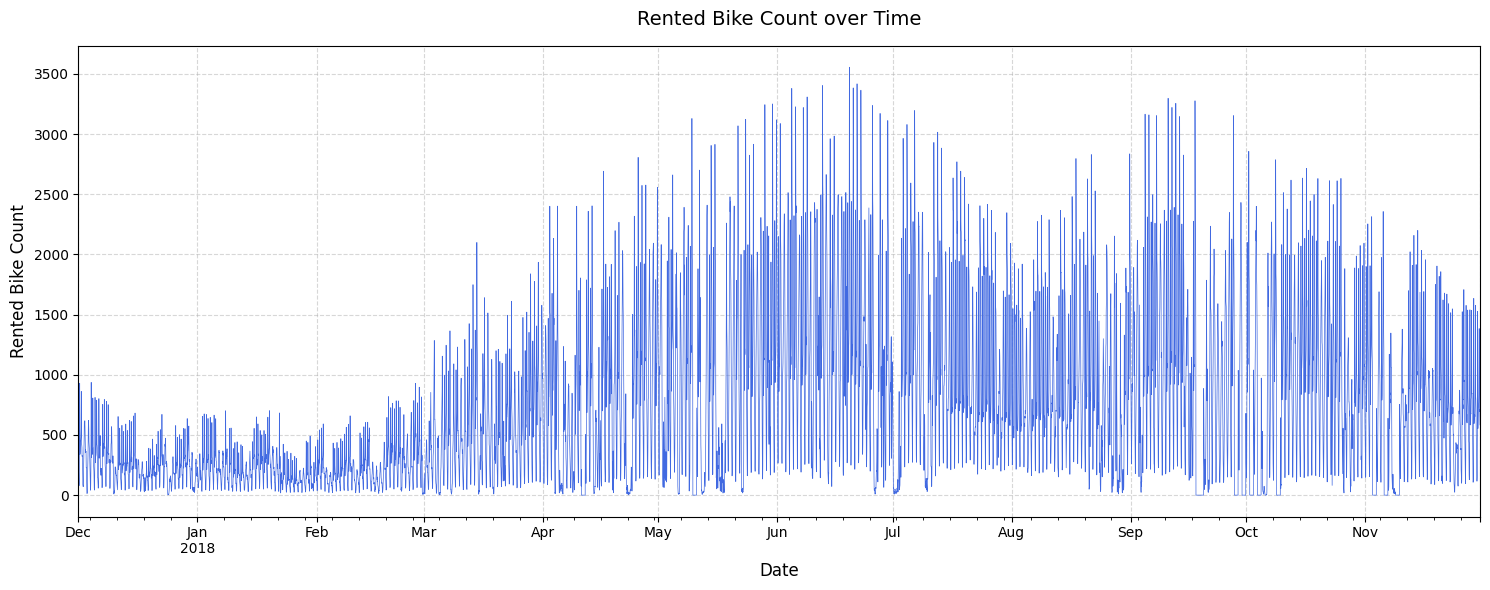

In [8]:
# X축으로 datetime 인덱스를 사용하여 rented_bike_count 시각화하기
plt.figure(figsize=(15, 6))
df['rented_bike_count'].plot(linewidth=0.5, color='royalblue')

# 그래프 제목 및 축 레이블 설정
plt.title('Rented Bike Count over Time', fontsize=14, pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rented Bike Count', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

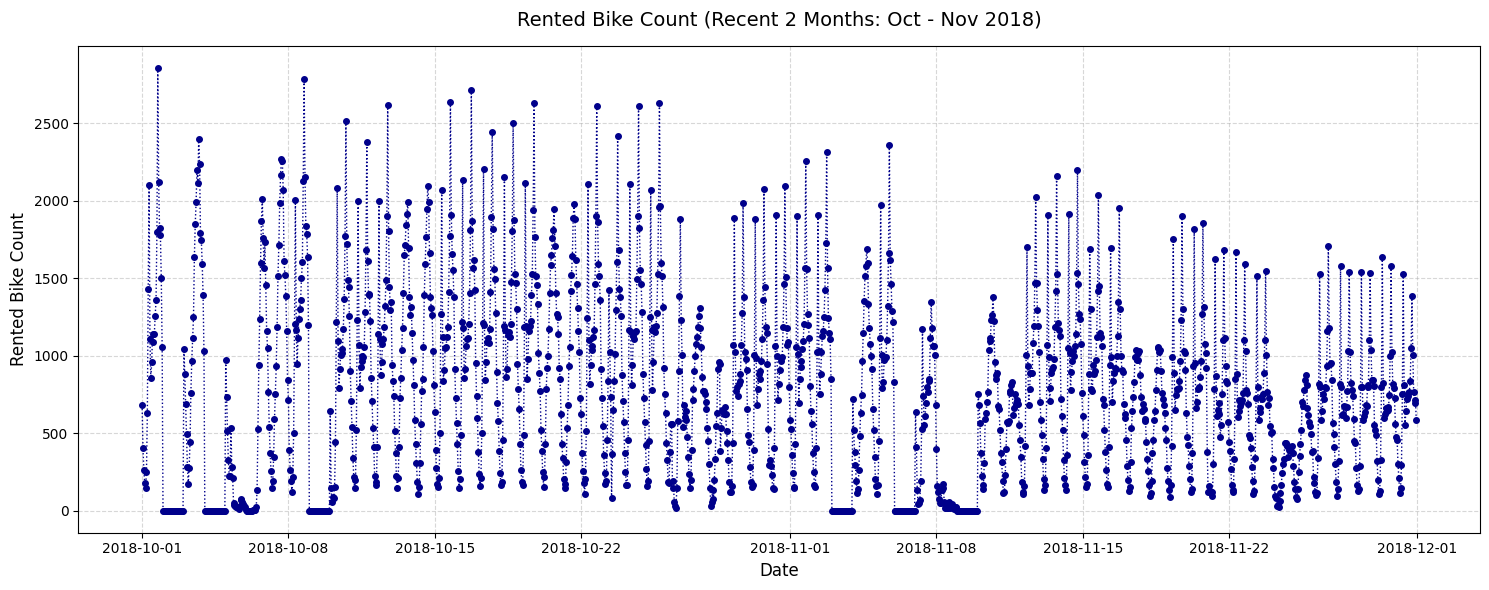

In [9]:
# 데이터프레임의 인덱스가 DatetimeIndex이므로, 슬라이싱을 통해 최근 2달(2018-10-01 ~ 2018-11-30) 데이터를 필터링합니다.
recent_two_months = df.loc['2018-10-01':'2018-12-01']

# 시각화 설정
plt.figure(figsize=(15, 6))
plt.plot(recent_two_months.index, recent_two_months['rented_bike_count'],  marker='o',markersize=4, color='darkblue',linestyle=':',linewidth=1)

# 그래프 제목 및 축 레이블 설정
plt.title('Rented Bike Count (Recent 2 Months: Oct - Nov 2018)', fontsize=14, pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rented Bike Count', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
## rented_bike_count 값이 0인 경우 확인
df[(df.index >= '2018-11-08') & (df.index <= '2018-11-11')].head(50)

,date,rented_bike_count,hour,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,seasons,holiday,functioning_day,month,day_name,dayofweek
datetime,,,,,,,,,,,,,,,,,
2018-11-08 00:00:00,08/11/2018,395,0,12.9,70,1.8,2000,7.5,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 01:00:00,08/11/2018,158,1,11.9,77,1.1,1634,7.9,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 02:00:00,08/11/2018,122,2,11.8,84,1.6,1874,9.1,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 03:00:00,08/11/2018,78,3,11.8,86,1.6,1819,9.5,0.00,0.5,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 04:00:00,08/11/2018,50,4,10.8,87,1.7,956,8.7,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 05:00:00,08/11/2018,49,5,10.8,89,1.6,957,9.0,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 06:00:00,08/11/2018,136,6,10.6,90,1.6,1065,9.0,0.00,1.5,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 07:00:00,08/11/2018,174,7,10.9,88,1.8,1866,8.9,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 08:00:00,08/11/2018,148,8,10.6,89,1.5,689,8.8,0.02,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3


### + 데이터정제(data cleansing)
- functioning_day	== No 인 경우 rented_bike_count가 0 해당 행(row)은 삭제

In [11]:
df = df[df['functioning_day'] == 'Yes']
print(df.info())
df[(df.index >= '2018-11-08') & (df.index <= '2018-11-11')].head(50)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8465 entries, 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8465 non-null   object 
 1   rented_bike_count      8465 non-null   int64  
 2   hour                   8465 non-null   int64  
 3   temperature            8465 non-null   float64
 4   humidity               8465 non-null   int64  
 5   wind_speed_ms          8465 non-null   float64
 6   visibility_10m         8465 non-null   int64  
 7   dew_point_temperature  8465 non-null   float64
 8   solar_radiation_mjm2   8465 non-null   float64
 9   rainfallmm             8465 non-null   float64
 10  snowfall_cm            8465 non-null   float64
 11  seasons                8465 non-null   object 
 12  holiday                8465 non-null   object 
 13  functioning_day        8465 non-null   object 
 14  month               

,date,rented_bike_count,hour,temperature,humidity,wind_speed_ms,visibility_10m,dew_point_temperature,solar_radiation_mjm2,rainfallmm,snowfall_cm,seasons,holiday,functioning_day,month,day_name,dayofweek
datetime,,,,,,,,,,,,,,,,,
2018-11-08 00:00:00,08/11/2018,395,0,12.9,70,1.8,2000,7.5,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 01:00:00,08/11/2018,158,1,11.9,77,1.1,1634,7.9,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 02:00:00,08/11/2018,122,2,11.8,84,1.6,1874,9.1,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 03:00:00,08/11/2018,78,3,11.8,86,1.6,1819,9.5,0.00,0.5,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 04:00:00,08/11/2018,50,4,10.8,87,1.7,956,8.7,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 05:00:00,08/11/2018,49,5,10.8,89,1.6,957,9.0,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 06:00:00,08/11/2018,136,6,10.6,90,1.6,1065,9.0,0.00,1.5,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 07:00:00,08/11/2018,174,7,10.9,88,1.8,1866,8.9,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3
2018-11-08 08:00:00,08/11/2018,148,8,10.6,89,1.5,689,8.8,0.02,0.0,0.0,Autumn,No Holiday,Yes,11,Thursday,3


### 데이터탐색(EDA)
- 분포탐색(단변량)

In [12]:
df.columns

Index(['date', 'rented_bike_count', 'hour', 'temperature', 'humidity',
       'wind_speed_ms', 'visibility_10m', 'dew_point_temperature',
       'solar_radiation_mjm2', 'rainfallmm', 'snowfall_cm', 'seasons',
       'holiday', 'functioning_day', 'month', 'day_name', 'dayofweek'],
      dtype='object')

- 측정형변수의 분포(distribution) 탐색

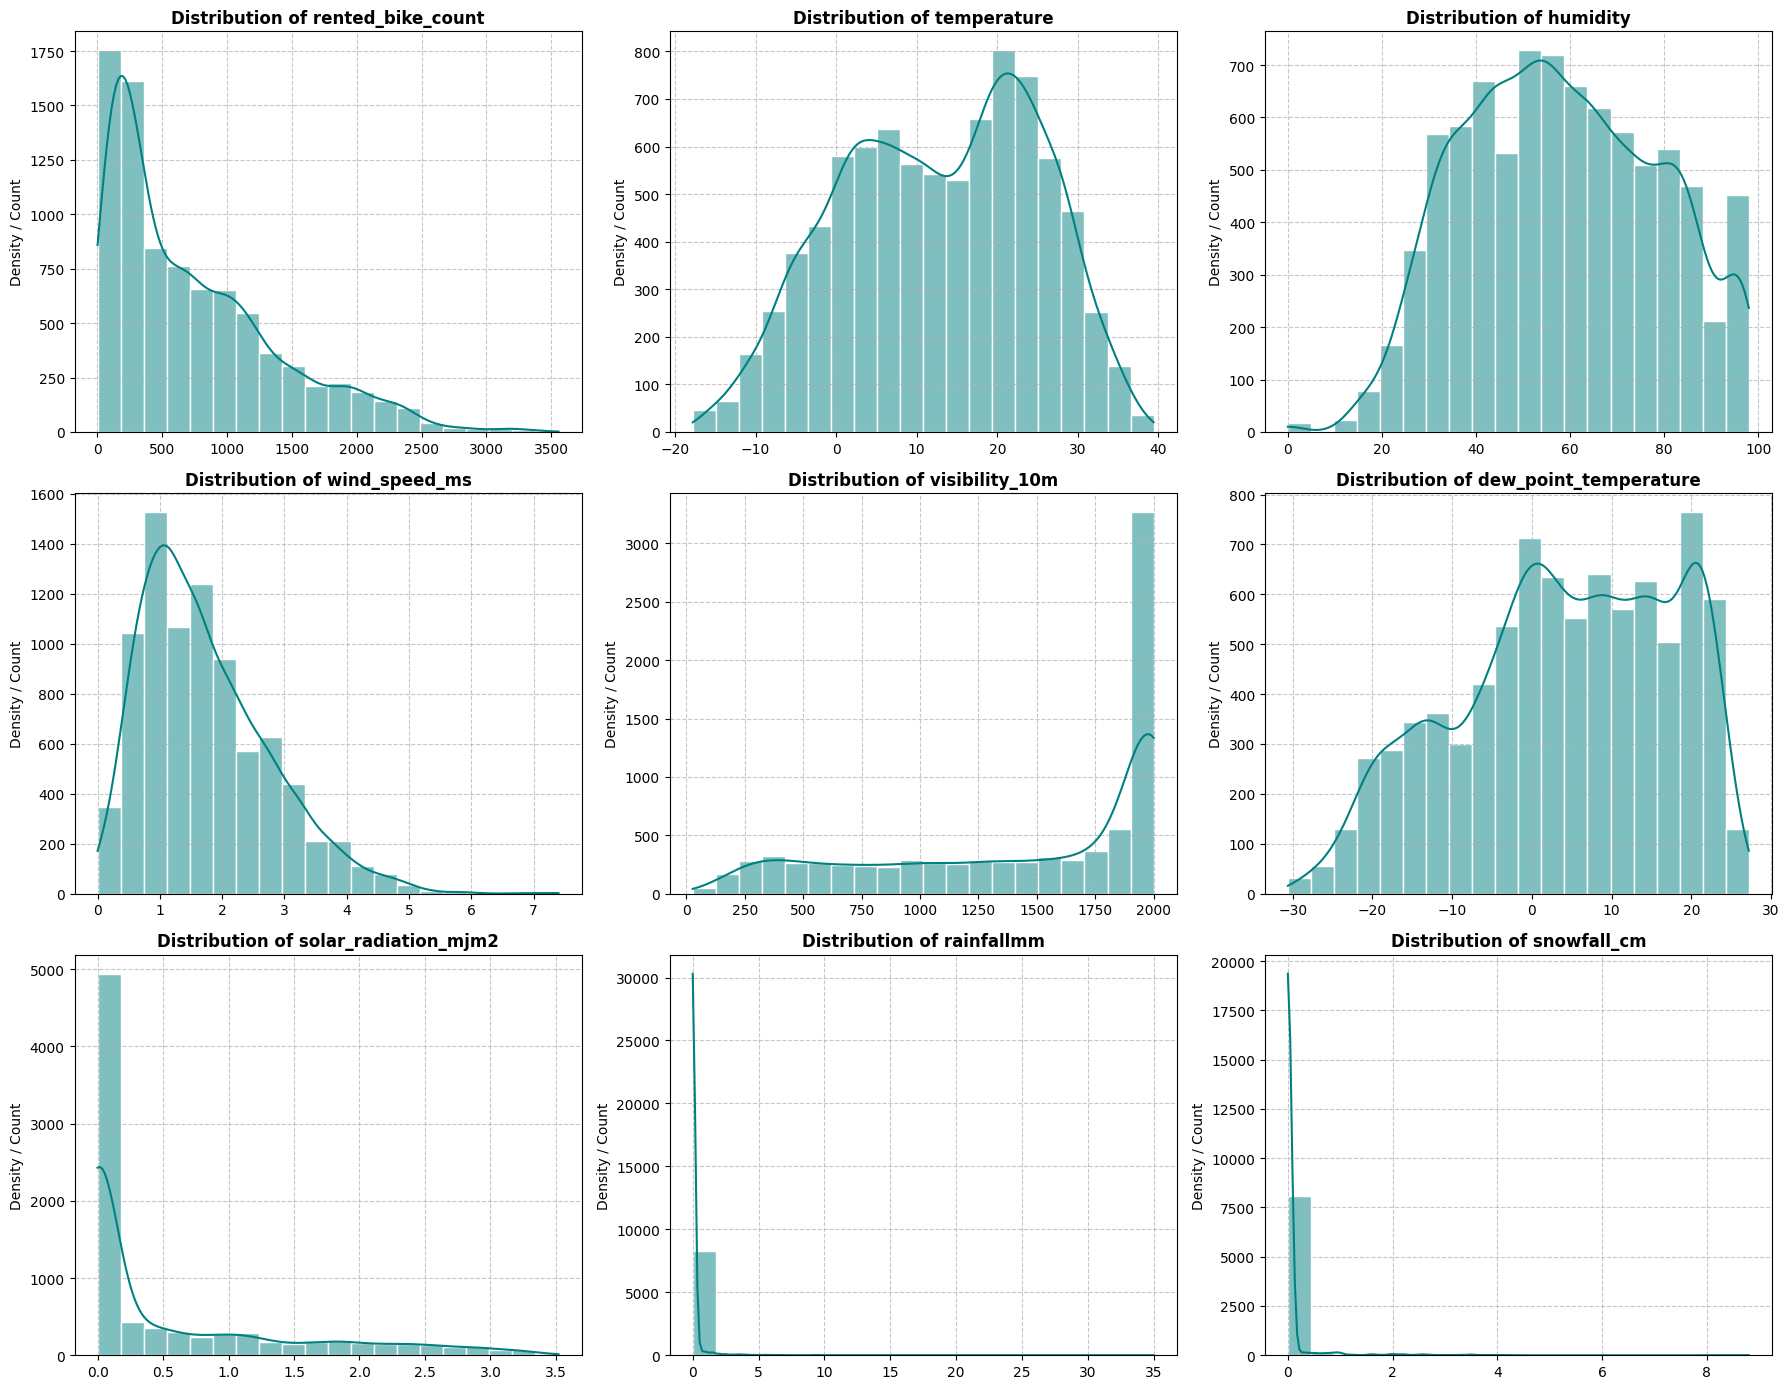

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 분포를 시각화할 대상 컬럼 리스트
dist_cols = [
    'rented_bike_count', 'temperature', 'humidity', 'wind_speed_ms',
    'visibility_10m', 'dew_point_temperature', 'solar_radiation_mjm2',
    'rainfallmm', 'snowfall_cm'
]

# 3x3 그리드로 서브플롯 설정
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(dist_cols):
    # 히스토그램과 KDE(밀도 곡선)를 함께 시각화
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=20, edgecolor='white')
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Density / Count')
    axes[i].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

- 범주형변수의 발생빈도 탐색

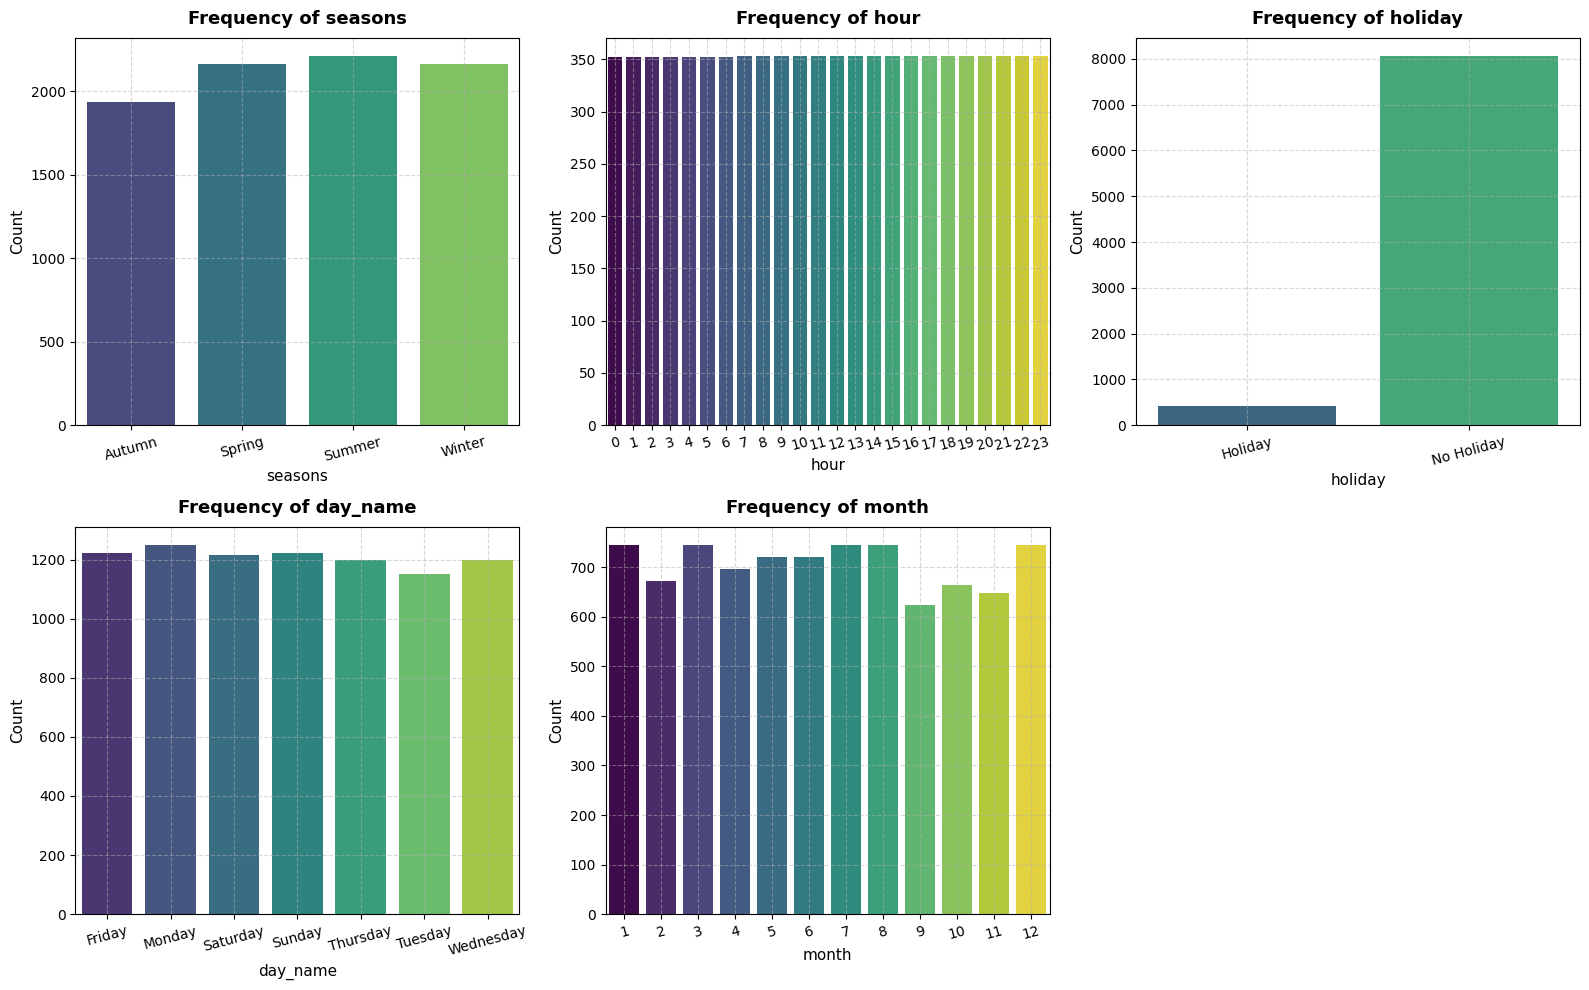

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 빈도를 분석할 범주형 변수 리스트 정의
cate_cols = ['seasons', 'hour', 'holiday', 'day_name', 'month']

# 3열 배열을 위한 행 수 계산
n_cols = 3
n_rows = int(np.ceil(len(cate_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cate_cols):
    # 각 카테고리별 빈도 데이터 계산 및 정렬
    val_counts = df[col].value_counts().sort_index()

    # 막대그래프 시각화
    sns.barplot(
        x=val_counts.index,
        y=val_counts.values,
        ax=axes[i],
        palette='viridis',
        hue=val_counts.index,
        legend=False
    )

    axes[i].set_title(f'Frequency of {col}', fontsize=13, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel('Count', fontsize=11)
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].tick_params(axis='x', rotation=15)

# 빈 하위 그래프 제거
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- 이변량분석: 산점도/히트맵

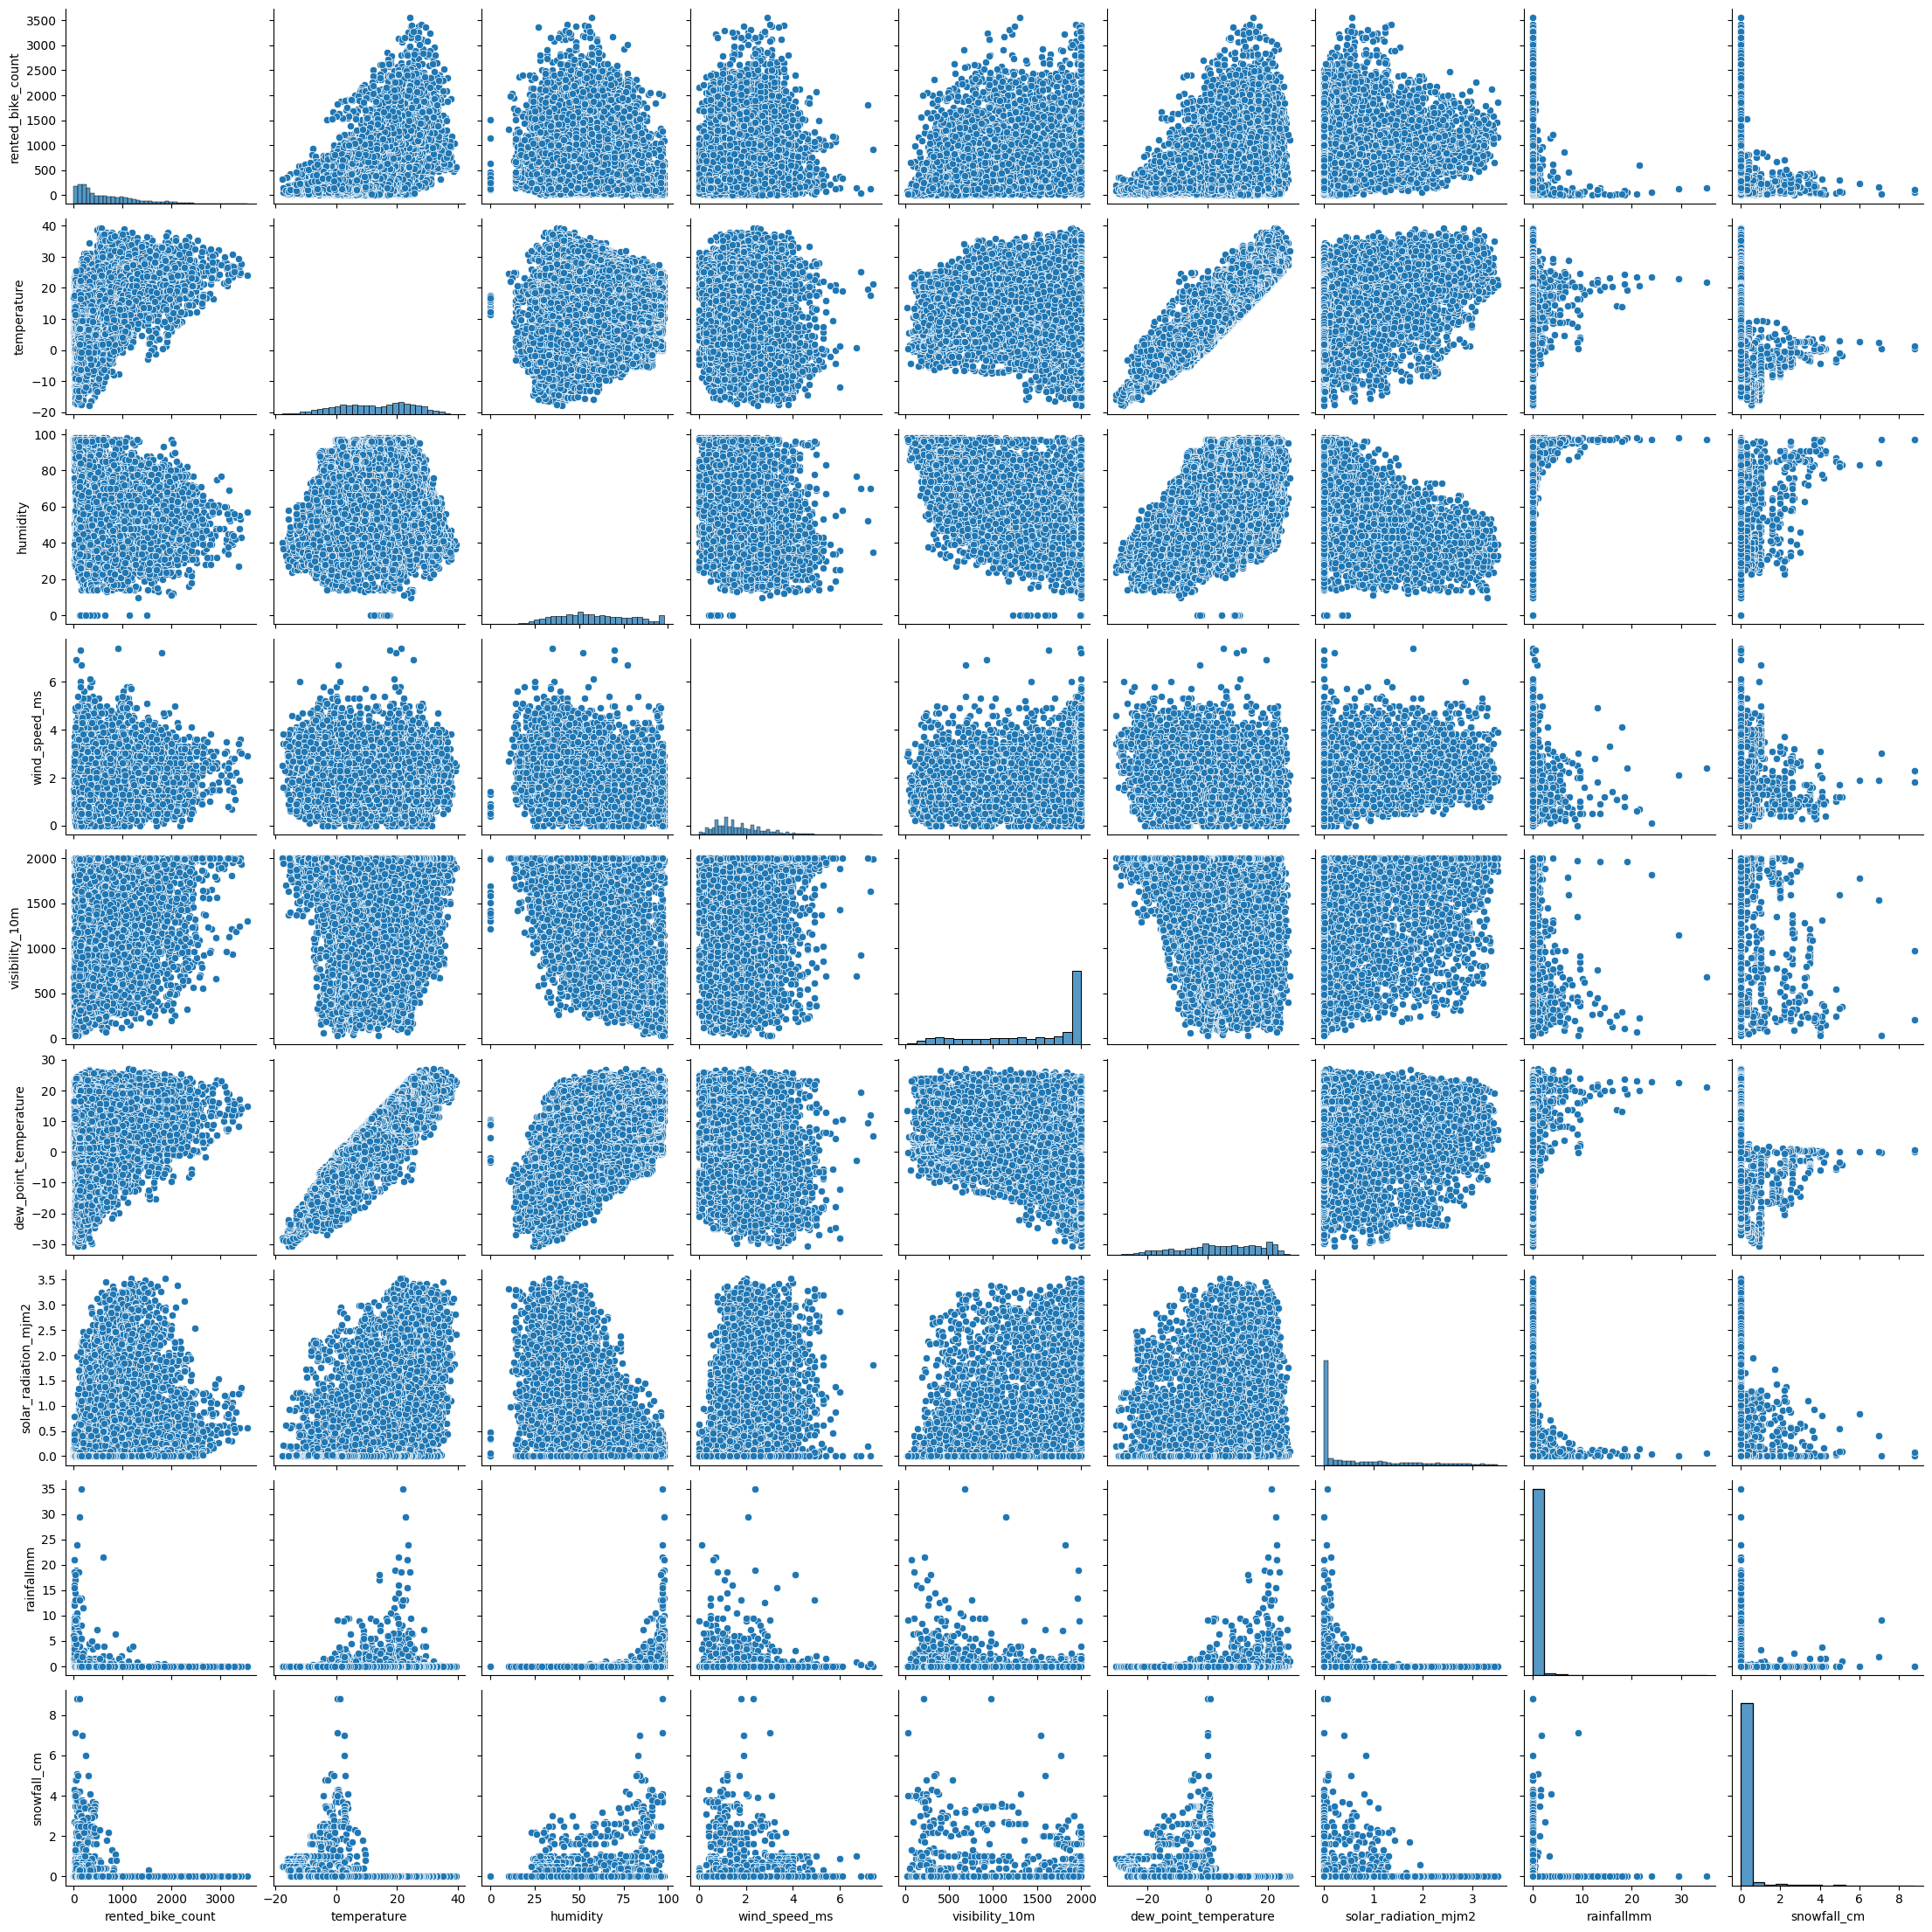

In [15]:
# prompt:  'rented_bike_count', 'temperature', 'humidity', 'wind_speed_ms','visibility_10m','dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm','snowfall_cm' 컬럼을 대상으로 seaborn에서 제공하는 산점도 코드를 제공해주세요
scatter_cols = ['rented_bike_count', 'temperature', 'humidity', 'wind_speed_ms','visibility_10m','dew_point_temperature', 'solar_radiation_mjm2', 'rainfallmm','snowfall_cm']

import matplotlib.pyplot as plt
sns.pairplot(df[scatter_cols])
plt.show()

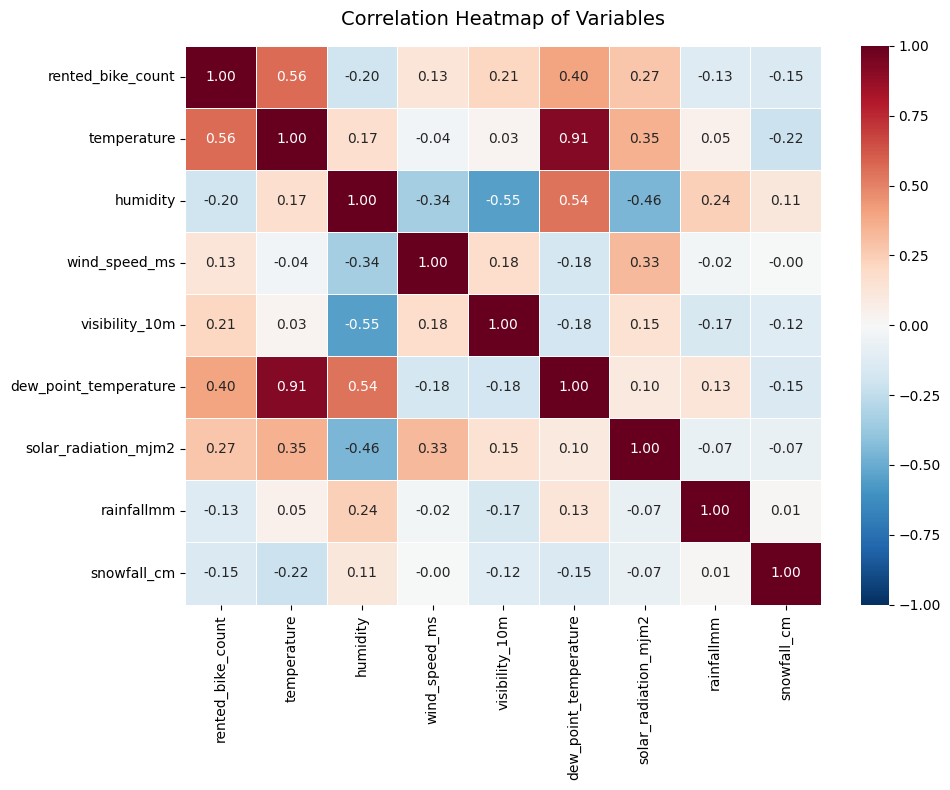

In [16]:
# 지정된 컬럼들 간의 상관계수 행렬 계산
corr_matrix = df[scatter_cols].corr()

# 히트맵 시각화 설정
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          # 각 셀에 숫자(상관계수) 표시
    cmap='RdBu_r',       # 붉은색(양의 상관관계) - 파란색(음의 상관관계) 컬러맵
    vmin=-1, vmax=1,     # 상관계수의 범위 제한
    linewidths=0.5,      # 셀 사이의 간격선 두께
    fmt='.2f'            # 소수점 둘째 자리까지 표시
)

plt.title('Correlation Heatmap of Variables', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

- 독립변수와 종속변수간의 관계 : 연속형 독립변수('temperature', 'humidity' 'wind_speed_ms','visibility_10m', 'dew_point_temperature','solar_radiation_mjm2','rainfallmm', 'snowfall_cm') bining 그룹별 rented_bike_count 중앙값(평균)

- binning 결과그룹별 boxplot

- 독립변수와 종속변수간의 관계 : 범주형 독립변수

- 범주형 독립변수와 종속변수간의 관계